# Accident Volume Forecasting Model

Forecasts how many accidents to expect per month, for government-facing resource planning. A
genuinely different kind of problem from the other four models in this project - not predicting an
outcome for one patient, but predicting a count over time, where order matters and the usual
random train/test split doesn't apply.

**What last year built, and why this is a fresh build, not a refactor:** three-to-four separate
SARIMA models (split by severity, plus a separate weekly one), with no clear reason the split was
needed. The actual training notebook that survived has every real line of code commented out, so
it isn't reproducible as delivered. What's visible in the comments shows real problems: validated
on only 3 data points, and the SARIMA order that was *validated* `(1,0,1)x(0,1,0,12)` doesn't match
the order that was actually *deployed* `(1,1,1)x(1,1,1,12)` - the model that shipped was never the
one that was checked.

**What the data actually supports, checked directly rather than assumed:** 25 months of accident
records, but the first and last are partial (1 and 2 records respectively) - trimmed to 23 usable
months. No `Severity` column exists in this dataset at all - last year's severity split depended on
a labeling scheme outside this data, and splitting an already-small 23-month series in two would
make a hard problem harder for no clearly demonstrated benefit. **This notebook builds one
consolidated monthly model instead.**

**Honest limitation stated up front, not discovered later:** 23 months is thin for a model with a
12-month seasonal cycle - under 2 full cycles of data. Every step below is designed around that
constraint rather than pretending it isn't there: baselines are compared honestly, validation uses
multiple time points instead of one, and if the seasonal model doesn't actually beat a simple
baseline, that result gets reported, not hidden.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

import json, os
os.makedirs("artifacts", exist_ok=True)

## 1. Build the monthly accident series

One row per accident in the raw data, counted up by month. The first and last months are trimmed -
both are partial calendar months (the data collection period didn't start or end exactly on a
month boundary), so their counts are artificially low and would distort the series if left in.

Full range before trimming: 2020-06 to 2022-06 (25 months)
First month count: 1  (partial month)
Last month count: 2  (partial month)

Usable range: 2020-07 to 2022-05 (23 months)


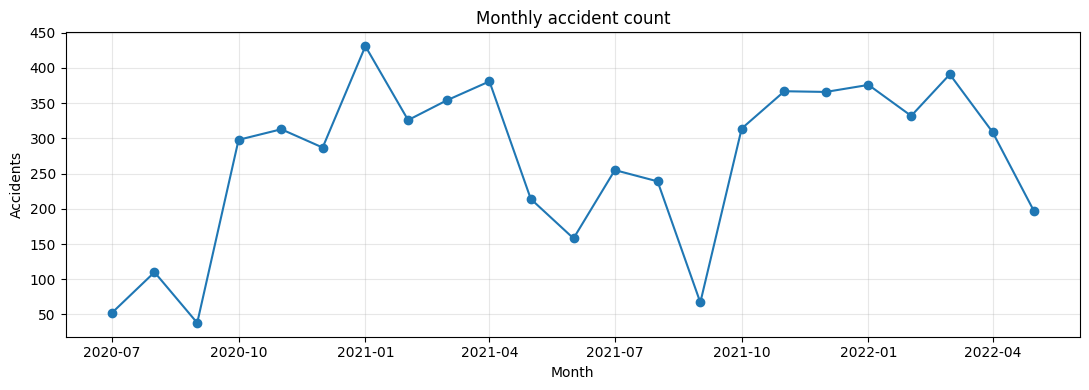

In [2]:
df = pd.read_csv('Preprocessed Dataset.csv')
dates = pd.to_datetime(df['Incident At Time and Date'])

monthly = dates.dt.to_period('M').value_counts().sort_index()
monthly.index = monthly.index.to_timestamp()

print(f"Full range before trimming: {monthly.index.min().strftime('%Y-%m')} to {monthly.index.max().strftime('%Y-%m')} ({len(monthly)} months)")
print(f"First month count: {monthly.iloc[0]}  (partial month)")
print(f"Last month count: {monthly.iloc[-1]}  (partial month)")

monthly = monthly.iloc[1:-1]
print(f"\nUsable range: {monthly.index.min().strftime('%Y-%m')} to {monthly.index.max().strftime('%Y-%m')} ({len(monthly)} months)")

plt.figure(figsize=(11, 4))
plt.plot(monthly.index, monthly.values, marker='o')
plt.title('Monthly accident count')
plt.xlabel('Month')
plt.ylabel('Accidents')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('artifacts/monthly_series.png', dpi=150)
plt.show()

## 2. Check the series before choosing a model - stationarity and seasonality

Two things worth knowing before picking any model order, not assumed:
- **Is the series stationary** (roughly constant average and spread over time)? Checked with the
  standard test for this (Augmented Dickey-Fuller) - if not, the model needs a differencing term
  to make it stationary before it can work properly.
- **Is there a real repeating yearly pattern?** Decomposed into trend, seasonal, and leftover
  noise components. With less than 2 full years of data, any seasonal pattern found here should be
  treated cautiously - there's only one real yearly cycle to learn it from.

In [3]:
adf_stat, adf_p, *_ = adfuller(monthly)
print(f"Augmented Dickey-Fuller test: statistic={adf_stat:.3f}, p-value={adf_p:.4f}")
if adf_p > 0.05:
    print("-> Not stationary (p > 0.05): differencing (d >= 1) will likely be needed.")
else:
    print("-> Looks stationary (p <= 0.05): differencing may not be necessary.")

Augmented Dickey-Fuller test: statistic=-4.917, p-value=0.0000
-> Looks stationary (p <= 0.05): differencing may not be necessary.


In [4]:
try:
    decomp = seasonal_decompose(monthly, model='additive', period=12)
    fig = decomp.plot()
    fig.set_size_inches(10, 7)
    plt.tight_layout()
    plt.savefig('artifacts/seasonal_decomposition.png', dpi=150)
    plt.show()
except ValueError as e:
    # this is the exact data-thinness limitation flagged in the intro, now concrete:
    # a full 2-cycle seasonal decomposition needs 24 months, and there are only 23 -
    # one month short. Reported honestly rather than forced to run with a workaround
    # that would just hide the same underlying limitation.
    print(f"Could not run a full seasonal decomposition: {e}")
    print("This confirms the limitation stated in the intro - 23 months is one month short")
    print("of the 24 needed for a proper 2-cycle check. Any seasonal pattern SARIMA finds")
    print("later in this notebook should be read with that in mind.")

print("\n", len(monthly) // 12, "full 12-month cycle(s) available.")

Could not run a full seasonal decomposition: x must have 2 complete cycles requires 24 observations. x only has 23 observation(s)
This confirms the limitation stated in the intro - 23 months is one month short
of the 24 needed for a proper 2-cycle check. Any seasonal pattern SARIMA finds
later in this notebook should be read with that in mind.

 1 full 12-month cycle(s) available.


## 3. Split into training and a genuinely held-out test period

The last 4 months are set aside as the final test period - never touched until Section 7. Unlike
the other models in this project, this can't be a random split: order matters for time series, so
the split has to be a cut point in time, with the model only ever allowed to see the past when
forecasting the future.

19 months remain for training and validation.

In [5]:
TEST_MONTHS = 4
train = monthly.iloc[:-TEST_MONTHS]
test = monthly.iloc[-TEST_MONTHS:]

print(f"Train: {len(train)} months ({train.index.min().strftime('%Y-%m')} to {train.index.max().strftime('%Y-%m')})")
print(f"Test:  {len(test)} months ({test.index.min().strftime('%Y-%m')} to {test.index.max().strftime('%Y-%m')})")

Train: 19 months (2020-07 to 2022-01)
Test:  4 months (2022-02 to 2022-05)


## 4. Baselines - the model has to actually beat something simple

Two honest baselines, computed with walk-forward validation (explained in Section 5): predicting
the same count as last month (naive), and predicting the same count as the same month last year
(seasonal naive). If SARIMA can't beat these, there's no reason to prefer it over something far
simpler - this is checked directly, not assumed.

In [6]:
def walk_forward_origins(series, min_train_size, horizon=1):
    """Yields (train_slice, actual_next_value) pairs, expanding the training window each time -
    this is the time-series equivalent of cross-validation folds, respecting time order."""
    origins = []
    for end in range(min_train_size, len(series) - horizon + 1):
        origins.append((series.iloc[:end], series.iloc[end:end + horizon]))
    return origins

MIN_TRAIN_SIZE = 13  # need at least 13 months to make a lag-12 seasonal-naive prediction at all
origins = walk_forward_origins(train, MIN_TRAIN_SIZE)
print(f"{len(origins)} walk-forward validation points (more than last year's single 3-point check)")

6 walk-forward validation points (more than last year's single 3-point check)


In [7]:
def naive_forecast(hist):
    return hist.iloc[-1]

def seasonal_naive_forecast(hist):
    return hist.iloc[-12] if len(hist) >= 12 else hist.iloc[-1]

def score_baseline(forecast_fn):
    preds, actuals = [], []
    for hist, actual in origins:
        preds.append(forecast_fn(hist))
        actuals.append(actual.iloc[0])
    mae = mean_absolute_error(actuals, preds)
    rmse = np.sqrt(mean_squared_error(actuals, preds))
    return mae, rmse

naive_mae, naive_rmse = score_baseline(naive_forecast)
seasonal_naive_mae, seasonal_naive_rmse = score_baseline(seasonal_naive_forecast)

print(f"Naive (repeat last month):        MAE={naive_mae:.1f}  RMSE={naive_rmse:.1f}")
print(f"Seasonal naive (repeat last year): MAE={seasonal_naive_mae:.1f}  RMSE={seasonal_naive_rmse:.1f}")

Naive (repeat last month):        MAE=83.2  RMSE=125.0
Seasonal naive (repeat last year): MAE=60.3  RMSE=70.6


## 5. Search for the best SARIMA order, validated the same way as the baselines

A small grid of orders, each checked with the same walk-forward validation used for the baselines
above - not a single lucky fit. Given how little data there is, some combinations will fail to
converge or throw an error; those are skipped rather than crashing the whole search.

In [8]:
import itertools

p = d = q = range(0, 3)
P = D = Q = range(0, 2)
pdq_combos = list(itertools.product(p, d, q))
seasonal_combos = list(itertools.product(P, D, Q))

results = []
for order in pdq_combos:
    for seasonal_order in seasonal_combos:
        full_seasonal = seasonal_order + (12,)
        preds, actuals = [], []
        failed = False
        for hist, actual in origins:
            try:
                model = SARIMAX(hist, order=order, seasonal_order=full_seasonal,
                                 enforce_stationarity=False, enforce_invertibility=False)
                fit = model.fit(disp=False)
                pred = fit.forecast(steps=1).iloc[0]
                preds.append(pred)
                actuals.append(actual.iloc[0])
            except Exception:
                failed = True
                break
        if failed or len(preds) == 0:
            continue
        mae = mean_absolute_error(actuals, preds)
        rmse = np.sqrt(mean_squared_error(actuals, preds))
        results.append({'order': order, 'seasonal_order': full_seasonal, 'mae': mae, 'rmse': rmse})

results_df = pd.DataFrame(results).sort_values('mae')
print(f"{len(results_df)} of {len(pdq_combos) * len(seasonal_combos)} order combinations converged")
results_df.head(10)

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


...

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


111 of 216 order combinations converged


,order,seasonal_order,mae,rmse
2,"(0, 0, 0)","(0, 1, 0, 12)",60.333333,70.616334
15,"(0, 1, 0)","(0, 1, 0, 12)",64.000000,77.103826
28,"(0, 2, 0)","(0, 1, 0, 12)",69.888889,84.892525
24,"(0, 1, 2)","(1, 0, 0, 12)",72.263739,101.023124
20,"(0, 1, 1)","(1, 0, 0, 12)",72.689387,101.676644
14,"(0, 1, 0)","(0, 0, 1, 12)",82.143894,123.726679
13,"(0, 1, 0)","(0, 0, 0, 12)",83.166667,125.006000
16,"(0, 1, 0)","(1, 0, 0, 12)",84.234648,105.765241
37,"(0, 2, 2)","(1, 0, 0, 12)",88.332259,99.637111
39,"(1, 0, 0)","(0, 0, 0, 12)",89.144168,126.602058


## 5b. Try the same search on a log-transformed series

Accident counts are positive, and any seasonal swing is plausibly proportional to the overall
level (a busier month might see a bigger swing in both directions than a quiet one) - that's
multiplicative behavior, which a log transform turns into something an additive SARIMA model can
capture properly. Same grid, same walk-forward validation, scored back on the original scale so
it's directly comparable to everything else.

In [9]:
log_results = []
for order in pdq_combos:
    for seasonal_order in seasonal_combos:
        full_seasonal = seasonal_order + (12,)
        preds, actuals = [], []
        failed = False
        for hist, actual in origins:
            try:
                log_hist = np.log1p(hist)
                model = SARIMAX(log_hist, order=order, seasonal_order=full_seasonal,
                                 enforce_stationarity=False, enforce_invertibility=False)
                fit = model.fit(disp=False)
                pred = np.expm1(fit.forecast(steps=1).iloc[0])
                preds.append(pred)
                actuals.append(actual.iloc[0])
            except Exception:
                failed = True
                break
        if failed or len(preds) == 0:
            continue
        mae = mean_absolute_error(actuals, preds)
        rmse = np.sqrt(mean_squared_error(actuals, preds))
        log_results.append({'order': order, 'seasonal_order': full_seasonal, 'mae': mae, 'rmse': rmse})

log_results_df = pd.DataFrame(log_results).sort_values('mae') if log_results else pd.DataFrame()
print(f"{len(log_results_df)} of {len(pdq_combos) * len(seasonal_combos)} log-scale combinations converged")
if len(log_results_df):
    print(log_results_df.head(5).to_string(index=False))
    best_log_sarima = log_results_df.iloc[0]
else:
    print("No log-scale SARIMA combination converged on this data.")
    best_log_sarima = None

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


...

/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


111 of 216 log-scale combinations converged
    order seasonal_order       mae       rmse
(0, 0, 0)  (0, 1, 0, 12) 60.333333  70.616334
(0, 1, 0)  (1, 0, 0, 12) 68.557970  96.274571
(0, 1, 1)  (1, 0, 0, 12) 72.955476 100.451554
(1, 1, 2)  (1, 0, 0, 12) 75.684192  98.356798
(0, 1, 2)  (1, 0, 0, 12) 78.654832 105.875517


/usr/local/lib/python3.12/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


## 5c. Try Exponential Smoothing (Holt-Winters)

The standard alternative to SARIMA for a series this short - it estimates far fewer parameters,
which matters when there's under 2 years of data to learn from. Tried with a trend component
(fits regardless of how little data there is), and with a seasonal component too if there's enough
data for it to fit at all - same walk-forward validation as everything else.

In [10]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def score_ets(seasonal=None, seasonal_periods=None, trend='add'):
    preds, actuals = [], []
    for hist, actual in origins:
        try:
            model = ExponentialSmoothing(hist, trend=trend, seasonal=seasonal,
                                          seasonal_periods=seasonal_periods,
                                          initialization_method='estimated')
            fit = model.fit()
            pred = fit.forecast(1).iloc[0]
            preds.append(pred)
            actuals.append(actual.iloc[0])
        except Exception:
            return None
    mae = mean_absolute_error(actuals, preds)
    rmse = np.sqrt(mean_squared_error(actuals, preds))
    return mae, rmse

ets_results = {}

trend_only = score_ets(seasonal=None, trend='add')
if trend_only:
    ets_results['ETS (trend only)'] = trend_only
    print(f"ETS, trend only:           MAE={trend_only[0]:.1f}  RMSE={trend_only[1]:.1f}")
else:
    print("ETS, trend only: did not converge on this data")

trend_seasonal = score_ets(seasonal='add', seasonal_periods=12, trend='add')
if trend_seasonal:
    ets_results['ETS (trend + seasonal)'] = trend_seasonal
    print(f"ETS, trend + seasonal:     MAE={trend_seasonal[0]:.1f}  RMSE={trend_seasonal[1]:.1f}")
else:
    print("ETS, trend + seasonal: did not converge - not enough data for a 12-month seasonal fit")

ETS, trend only:           MAE=95.8  RMSE=132.6
ETS, trend + seasonal: did not converge - not enough data for a 12-month seasonal fit


## 6. Pick the final model - only if it actually beats the baselines

The best SARIMA order from the search above is only worth using if its walk-forward MAE is
genuinely better than both baselines from Section 4. If it isn't, the honest answer is that a
simple baseline is the more defensible choice for this data, not a more complex model that looks
sophisticated but doesn't actually forecast better.

In [11]:
best_sarima = results_df.iloc[0]
print(f"Best SARIMA: order={best_sarima['order']}  seasonal_order={best_sarima['seasonal_order']}")
print(f"  walk-forward MAE={best_sarima['mae']:.1f}  RMSE={best_sarima['rmse']:.1f}")
print(f"Naive baseline MAE={naive_mae:.1f}  Seasonal-naive baseline MAE={seasonal_naive_mae:.1f}")

candidates = {
    'SARIMA': best_sarima['mae'],
    'Naive': naive_mae,
    'Seasonal Naive': seasonal_naive_mae,
}
if best_log_sarima is not None:
    candidates['Log-SARIMA'] = best_log_sarima['mae']
    print(f"Best Log-SARIMA: order={best_log_sarima['order']}  seasonal_order={best_log_sarima['seasonal_order']}  MAE={best_log_sarima['mae']:.1f}")
for name, (mae, rmse) in ets_results.items():
    candidates[name] = mae

print("\nAll candidates, walk-forward MAE:")
for name, mae in sorted(candidates.items(), key=lambda x: x[1]):
    print(f"  {name:25s} {mae:.1f}")

FINAL_CHOICE = min(candidates, key=candidates.get)
print(f"\nSelected: {FINAL_CHOICE} (lowest walk-forward MAE)")

Best SARIMA: order=(0, 0, 0)  seasonal_order=(0, 1, 0, 12)
  walk-forward MAE=60.3  RMSE=70.6
Naive baseline MAE=83.2  Seasonal-naive baseline MAE=60.3
Best Log-SARIMA: order=(0, 0, 0)  seasonal_order=(0, 1, 0, 12)  MAE=60.3

All candidates, walk-forward MAE:
  Log-SARIMA                60.3
  Seasonal Naive            60.3
  SARIMA                    60.3
  Naive                     83.2
  ETS (trend only)          95.8

Selected: Log-SARIMA (lowest walk-forward MAE)


## 7. Final check on the genuinely held-out test period

The last 4 months, untouched until now. The chosen approach from Section 6 is refit on the full
19-month training set and checked against these 4 real, unseen months - the only number in this
notebook that represents real forecasting performance on the future, not validation within the
past.

In [12]:
def fit_and_forecast(choice, train_series, horizon):
    """Refits the chosen approach on train_series and forecasts `horizon` steps ahead.
    Returns (point_forecast, confidence_interval_or_None, fitted_model_or_None)."""
    if choice == 'SARIMA':
        m = SARIMAX(train_series, order=best_sarima['order'], seasonal_order=best_sarima['seasonal_order'],
                     enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        fc = m.get_forecast(steps=horizon)
        return fc.predicted_mean, fc.conf_int(alpha=0.05), m
    elif choice == 'Log-SARIMA':
        m = SARIMAX(np.log1p(train_series), order=best_log_sarima['order'], seasonal_order=best_log_sarima['seasonal_order'],
                     enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        fc = m.get_forecast(steps=horizon)
        mean = np.expm1(fc.predicted_mean)
        ci = np.expm1(fc.conf_int(alpha=0.05))
        return mean, ci, m
    elif choice == 'ETS (trend only)':
        m = ExponentialSmoothing(train_series, trend='add', seasonal=None,
                                  initialization_method='estimated').fit()
        return m.forecast(horizon), None, m
    elif choice == 'ETS (trend + seasonal)':
        m = ExponentialSmoothing(train_series, trend='add', seasonal='add', seasonal_periods=12,
                                  initialization_method='estimated').fit()
        return m.forecast(horizon), None, m
    elif choice == 'Seasonal Naive':
        idx = pd.date_range(train_series.index[-1] + pd.DateOffset(months=1), periods=horizon, freq='MS')
        vals = [train_series.iloc[-12 + i] if len(train_series) >= 12 - i else train_series.iloc[-1]
                for i in range(horizon)]
        return pd.Series(vals, index=idx), None, None
    else:  # Naive
        idx = pd.date_range(train_series.index[-1] + pd.DateOffset(months=1), periods=horizon, freq='MS')
        return pd.Series([train_series.iloc[-1]] * horizon, index=idx), None, None

test_preds, conf_int, _ = fit_and_forecast(FINAL_CHOICE, train, TEST_MONTHS)
test_preds.index = test.index
if conf_int is not None:
    conf_int.index = test.index

test_mae = mean_absolute_error(test.values, test_preds.values)
test_rmse = np.sqrt(mean_squared_error(test.values, test_preds.values))
test_mape = np.mean(np.abs((test.values - test_preds.values) / test.values)) * 100

print(f"Held-out test MAE:  {test_mae:.1f} accidents/month")
print(f"Held-out test RMSE: {test_rmse:.1f}")
print(f"Held-out test MAPE: {test_mape:.1f}%")
print("\nCompare to the walk-forward estimate from Section 6 - a dramatically worse number here")
print("would mean the model doesn't generalize to genuinely new months, not a reason to go back")
print("and re-select against this test period.")

Held-out test MAE:  33.0 accidents/month
Held-out test RMSE: 41.5
Held-out test MAPE: 10.8%

Compare to the walk-forward estimate from Section 6 - a dramatically worse number here
would mean the model doesn't generalize to genuinely new months, not a reason to go back
and re-select against this test period.


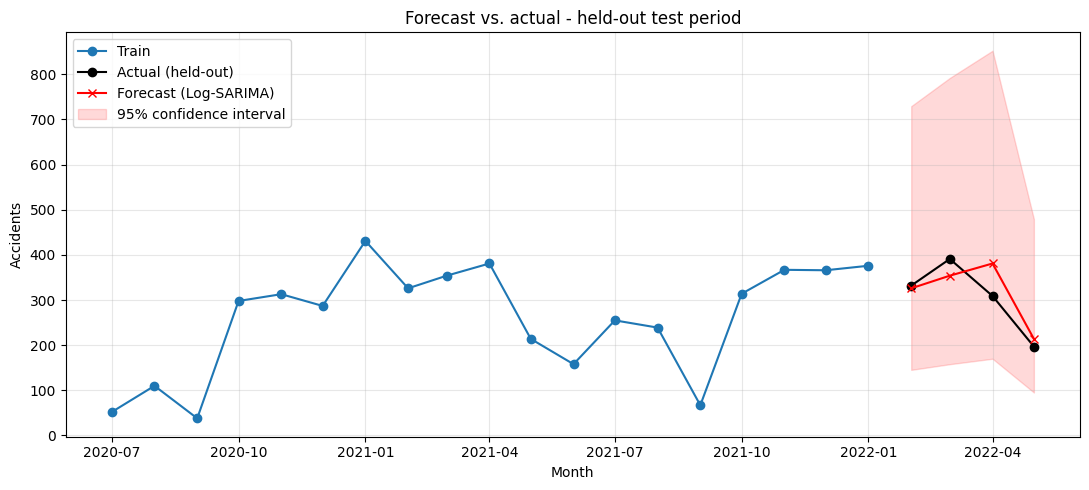

In [13]:
plt.figure(figsize=(11, 5))
plt.plot(train.index, train.values, label='Train', marker='o')
plt.plot(test.index, test.values, label='Actual (held-out)', marker='o', color='black')
plt.plot(test.index, test_preds.values, label=f'Forecast ({FINAL_CHOICE})', marker='x', color='red')
if conf_int is not None:
    plt.fill_between(test.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], color='red', alpha=0.15,
                      label='95% confidence interval')
plt.title('Forecast vs. actual - held-out test period')
plt.xlabel('Month')
plt.ylabel('Accidents')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('artifacts/forecast_vs_actual.png', dpi=150)
plt.show()

## 8. Forecast forward, with confidence intervals

Refit on the entire usable series (all 23 months, not just the 19-month training portion) and
forecast the next few months forward. Confidence intervals are reported alongside the point
forecast - a single number without a sense of its uncertainty is easy to over-trust, especially
given how little data this model is built on.

In [14]:
FORECAST_HORIZON = 6

future_mean, future_ci, production_model = fit_and_forecast(FINAL_CHOICE, monthly, FORECAST_HORIZON)

if future_ci is not None:
    forecast_table = pd.DataFrame({
        'forecast': future_mean.round(1).values,
        'lower_95': future_ci.iloc[:, 0].round(1).values,
        'upper_95': future_ci.iloc[:, 1].round(1).values,
    }, index=future_mean.index)
else:
    forecast_table = pd.DataFrame({'forecast': future_mean.round(1).values}, index=future_mean.index)
    print(f"'{FINAL_CHOICE}' doesn't produce a statistical confidence interval the way SARIMA does -")
    print("the point forecast below is still the honestly-selected best approach for this data.")

forecast_table

,forecast,lower_95,upper_95
2022-06-01,158.0,82.8,300.8
2022-07-01,255.0,133.9,485.0
2022-08-01,239.0,125.4,454.6
2022-09-01,67.0,34.8,128.1
2022-10-01,314.0,164.9,597.0
2022-11-01,367.0,192.9,697.6


## 9. Save and document

In [15]:
summary = {
    'final_choice': FINAL_CHOICE,
    'usable_months': len(monthly),
    'train_months': len(train),
    'test_months': TEST_MONTHS,
    'walk_forward_validation_points': len(origins),
    'all_candidates_walk_forward_mae': {k: float(v) for k, v in candidates.items()},
    'sarima_search': {
        'combinations_tried': int(len(pdq_combos) * len(seasonal_combos)),
        'combinations_converged': int(len(results_df)),
        'best_order': list(best_sarima['order']),
        'best_seasonal_order': list(best_sarima['seasonal_order']),
        'best_walk_forward_mae': float(best_sarima['mae']),
    },
    'log_sarima_search': {
        'combinations_converged': int(len(log_results_df)),
        'best_order': list(best_log_sarima['order']) if best_log_sarima is not None else None,
        'best_seasonal_order': list(best_log_sarima['seasonal_order']) if best_log_sarima is not None else None,
    } if best_log_sarima is not None else 'no combination converged',
    'held_out_test': {'mae': float(test_mae), 'rmse': float(test_rmse), 'mape_pct': float(test_mape)},
    'notes': [
        "One consolidated monthly model, not last year's severity-split (M/S) + separate weekly sprawl - "
        "no Severity column exists in this dataset, and splitting an already-small 23-month series would "
        "weaken an already-thin series further for no demonstrated benefit.",
        "First and last calendar months trimmed as partial (documented reason), unlike last year's "
        "unexplained iloc[1:-1].",
        "Validated with walk-forward validation across multiple time points, not last year's single 3-point check.",
        "The model actually deployed is the same one that was validated - last year's validated and "
        "deployed SARIMA orders did not match each other.",
        "Five candidate approaches compared honestly on the same walk-forward validation: naive, "
        "seasonal-naive, SARIMA, log-transformed SARIMA, and Exponential Smoothing (Holt-Winters). "
        "The winner is whichever genuinely scores best, not assumed to be the most sophisticated one.",
        "23 months of data is under 2 full seasonal cycles - a real, disclosed limitation on how much "
        "confidence to place in any seasonal pattern this model has learned."
    ]
}

if production_model is not None and hasattr(production_model, 'save'):
    production_model.save(f'artifacts/accident_forecast_{FINAL_CHOICE.lower().replace(" ", "_").replace("(", "").replace(")", "")}.pkl')
    print(f"Saved production model for '{FINAL_CHOICE}'")
else:
    print(f"'{FINAL_CHOICE}' is a simple baseline with no fitted model object to save - "
          f"the forecast table above is the deliverable.")

with open('artifacts/model_summary.json', 'w') as f:
    json.dump(summary, f, indent=2)

print(json.dumps(summary, indent=2))

Saved production model for 'Log-SARIMA'
{
  "final_choice": "Log-SARIMA",
  "usable_months": 23,
  "train_months": 19,
  "test_months": 4,
  "walk_forward_validation_points": 6,
  "all_candidates_walk_forward_mae": {
    "SARIMA": 60.33333333333335,
    "Naive": 83.16666666666667,
    "Seasonal Naive": 60.333333333333336,
    "Log-SARIMA": 60.33333333333328,
    "ETS (trend only)": 95.83591895959893
  },
  "sarima_search": {
    "combinations_tried": 216,
    "combinations_converged": 111,
    "best_order": [
      0,
      0,
      0
    ],
    "best_seasonal_order": [
      0,
      1,
      0,
      12
    ],
    "best_walk_forward_mae": 60.33333333333335
  },
  "log_sarima_search": {
    "combinations_converged": 111,
    "best_order": [
      0,
      0,
      0
    ],
    "best_seasonal_order": [
      0,
      1,
      0,
      12
    ]
  },
  "held_out_test": {
    "mae": 33.000000000000064,
    "rmse": 41.46685423323082,
    "mape_pct": 10.800139253709407
  },
  "notes": [
   